# MLIP



| # | Exercise | Key idea |
|---|---|---|
| 1 | Argon dimer in real units, and choosing the finite-difference step $h$ | $\mathbf F=-\nabla E$ |
| 2 | Curvature of three cutoff functions | smoothness at $r_c$ |
| 3 | Radial fingerprint $G^2$ of a carbon atom in graphene | descriptor as a smooth RDF |
| 4 | $G^4$: separating the angular and radial parts | role of $\eta$ and $\lambda$ |

Exercise 1 uses eV and Å, exercises 2–4 use Å. Only NumPy and Matplotlib are needed.

---
## Exercise 1. Argon dimer in real units and the finite-difference step
Lennard-Jones argon: $\epsilon=0.0104$ eV, $\sigma=3.40$ Å,
$$U(r)=4\epsilon\big[(\sigma/r)^{12}-(\sigma/r)^6\big],\qquad F(r)=\frac{24\epsilon}{r}\big[2(\sigma/r)^{12}-(\sigma/r)^6\big].$$
The central difference has a **truncation error** $\propto h^2$ (too large $h$) and a **round-off error** $\propto\varepsilon_{\rm mach}/h$ (too small $h$). We scan $h$ to find the sweet spot.

U(3.6) = -8.571 meV,  F(3.6) = +0.02063 eV/A
best step h = 1.8e-06 A, error = 5.9e-13 eV/A


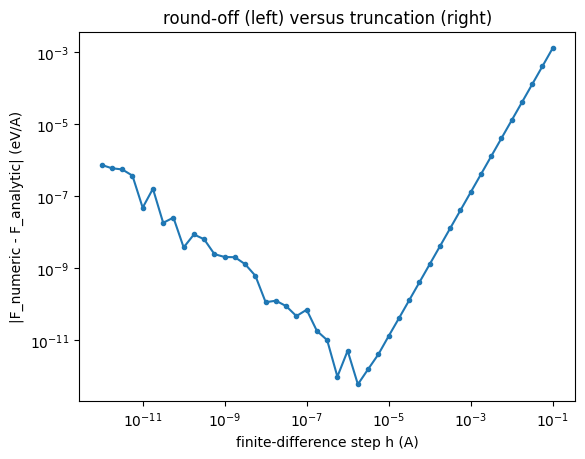

In [5]:
import numpy as np, matplotlib.pyplot as plt

eps, sig = 0.0104, 3.40                                   # eV, Angstrom
U = lambda r: 4 * eps * ((sig / r)**12 - (sig / r)**6)
F = lambda r: 24 * eps / r * (2 * (sig / r)**12 - (sig / r)**6)

r = 3.6                                                   # Angstrom, on the repulsive side of the minimum
print(f"U({r}) = {1000*U(r):.3f} meV,  F({r}) = {F(r):+.5f} eV/A")

hs = np.logspace(-12, -1, 45)
err = [abs(-(U(r + h) - U(r - h)) / (2 * h) - F(r)) for h in hs]
best = hs[np.argmin(err)]
print(f"best step h = {best:.1e} A, error = {min(err):.1e} eV/A")

plt.loglog(hs, err, "o-", ms=3)
plt.xlabel("finite-difference step h (A)"); plt.ylabel("|F_numeric - F_analytic| (eV/A)")
plt.title("round-off (left) versus truncation (right)"); plt.show()

**Your turn.** Theory predicts the best step near $h\sim\varepsilon_{\rm mach}^{1/3}\times(\text{length scale})$ with $\varepsilon_{\rm mach}\approx2\times10^{-16}$. Does your optimum agree? Repeat with the forward difference $-[U(r+h)-U(r)]/h$. Where is its optimum, and why is it worse?

forward: best step h = 1.0e-08 A, error = 5.5e-10 eV/A


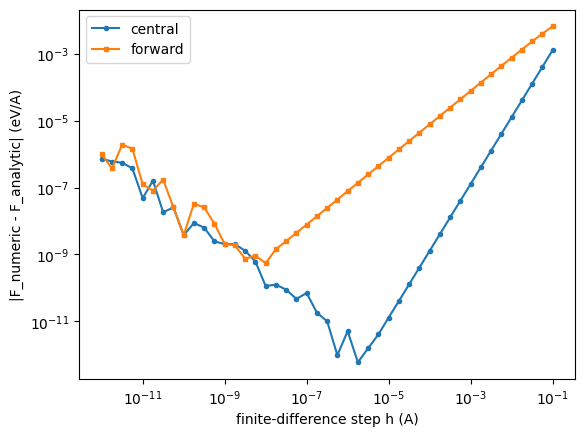

In [6]:
err_fwd = [abs(-(U(r + h) - U(r)) / h - F(r)) for h in hs]
best_fwd = hs[np.argmin(err_fwd)]
print(f"forward: best step h = {best_fwd:.1e} A, error = {min(err_fwd):.1e} eV/A")

plt.loglog(hs, err, "o-", ms=3, label="central")
plt.loglog(hs, err_fwd, "s-", ms=3, label="forward")
plt.xlabel("finite-difference step h (A)")
plt.ylabel("|F_numeric - F_analytic| (eV/A)")
plt.legend(); plt.show()

Central difference

The error has two parts. Round-off error grows as h gets smaller, because we subtract two nearly equal numbers and divide by a tiny h, so it scales like 1/h. Truncation error grows as h gets bigger, because the formula is only approximate, and for the central difference it scales like h². The best h is where the two are equal.

Theory says h ~ ε_mach^(1/3) × (length scale) ≈ 6×10⁻⁶ × L. The length scale is not σ. It is the distance over which U changes, L = (U/U‴)^(1/3) ≈ 0.3 Å, which gives h ≈ 2×10⁻⁶ Å.

My measured optimum is h ≈ 1.8×10⁻⁶ Å with an error of about 6×10⁻¹³ eV/Å. This agrees with the theory. On the plot, the left side (round-off) slopes down and is noisy, and the right side (truncation) slopes up with slope 2.

Forward difference

Its truncation error is only first order, about (h/2)|U″|, so it scales like h instead of h². Balancing this against the same round-off error gives h ~ ε_mach^(1/2) × L, so the optimum h is much smaller. My measured optimum is h ≈ 1.0e-08 Å, with an error of about 5.5e-10 eV/Å. On the plot the right side now has slope 1 instead of 2.

Why the forward difference is worse

The central difference cancels the O(h) error term, so its truncation error is O(h²) and its best accuracy scales like ε_mach^(2/3). The forward difference keeps the O(h) term, so its best accuracy only scales like ε_mach^(1/2). Since ε_mach is tiny, ε^(2/3) is much smaller than ε^(1/2), so the central difference reaches a far lower minimum error. Here the forward minimum error is about 1000 times larger.

---
## Exercise 2. Curvature of three cutoff functions
For energy conservation, the force (first derivative) must be continuous. For vibrational properties and stable integration, the **second** derivative should also be smooth. Compare at $r_c=5$ Å
- cosine: $\tfrac12[\cos(\pi r/r_c)+1]$,
- MTP-style: $(1-r/r_c)^2$,
- polynomial envelope with $p=6$.

cosine        : just inside rc  f = 2.5e-06,  f' = -9.9e-04,  f'' = +0.197
(1 - r/rc)^2  : just inside rc  f = 1.0e-06,  f' = -4.0e-04,  f'' = +0.080
envelope p=6  : just inside rc  f = 5.6e-08,  f' = -3.4e-05,  f'' = +0.013


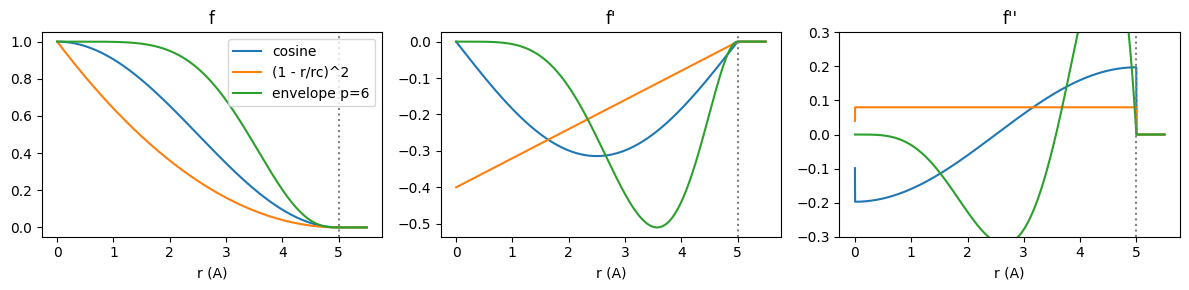

In [1]:
import numpy as np, matplotlib.pyplot as plt

rc = 5.0
r = np.linspace(0, 5.5, 5501); x = np.minimum(r / rc, 1)
cuts = {
    "cosine":       np.where(r < rc, 0.5 * (np.cos(np.pi * x) + 1), 0),
    "(1 - r/rc)^2": np.where(r < rc, (1 - x)**2, 0),
    "envelope p=6": np.where(r < rc, 1 - 28 * x**6 + 48 * x**7 - 21 * x**8, 0),
}
dr = r[1] - r[0]
fig, ax = plt.subplots(1, 3, figsize=(12, 3))
for name, f in cuts.items():
    d1 = np.gradient(f, dr); d2 = np.gradient(d1, dr)
    ax[0].plot(r, f, label=name); ax[1].plot(r, d1, label=name); ax[2].plot(r, d2, label=name)
    i = np.searchsorted(r, rc) - 5
    print(f"{name:14s}: just inside rc  f = {f[i]:.1e},  f' = {d1[i]:+.1e},  f'' = {d2[i]:+.3f}")
for a_, t in zip(ax, ("f", "f'", "f''")): a_.set_title(t); a_.axvline(rc, color="gray", ls=":"); a_.set_xlabel("r (A)")
ax[2].set_ylim(-0.3, 0.3); ax[0].legend(); plt.tight_layout(); plt.show()

**Your turn.** Rank the three functions by smoothness at $r_c$ (value, slope, curvature). The cosine and $(1-r/r_c)^2$ both have zero slope but nonzero curvature at $r_c$, so the forces are continuous while their derivatives jump. Which property (energy conservation in MD, or phonon frequencies from the Hessian) is affected by a curvature jump, and why?

FIRST PART: Ranking by smoothness at r_c (smoothest first)

Polynomial envelope, p = 6. Its value, slope and curvature all go to zero at r_c (f’’ just inside r_c is only +0.013 and tends to 0). It is smooth to second order.

(1 − r/r_c)². Its value and slope are zero, but f’’ jumps from +0.080 to 0, a small jump.

Cosine. Its value and slope are zero, but f’’ jumps from +0.197 to 0, the biggest jump. Analytically f’’ = ½(π/r_c)² ≈ 0.197.

SECOND PART: Which property is affected: the phonon frequencies from the Hessian.

ANSWER:  Energy conservation in MD depends on the force being continuous, so that no atom gets a sudden kick when a neighbour crosses r_c. Both the cosine and (1 − r/r_c)² have zero slope at r_c, so their forces are continuous and energy is conserved. A jump in f’’ only slightly hurts integration accuracy.

The Hessian (force constants) is built from the second derivative of the energy. A curvature jump means the force constants change discontinuously when a pair moves across r_c. This gives noisy or spurious shifts in phonon frequencies, and the error is largest for the cosine because its jump is biggest. The p = 6 envelope has no jump, so its Hessian is smooth.

---
## Exercise 3. Radial fingerprint of a carbon atom in graphene
$$G^2_i(R_s)=\sum_{j\ne i}e^{-\eta(r_{ij}-R_s)^2}f_c(r_{ij}).$$
In graphene ($d_{\rm CC}=1.42$ Å) each carbon has 3 first neighbours at 1.42 Å, 6 second neighbours at 2.46 Å and 3 third neighbours at 2.84 Å. We build a patch of the honeycomb lattice and compute the fingerprint of one atom.

shell at 1.420 A: 3 atoms
shell at 2.460 A: 6 atoms
shell at 2.840 A: 3 atoms


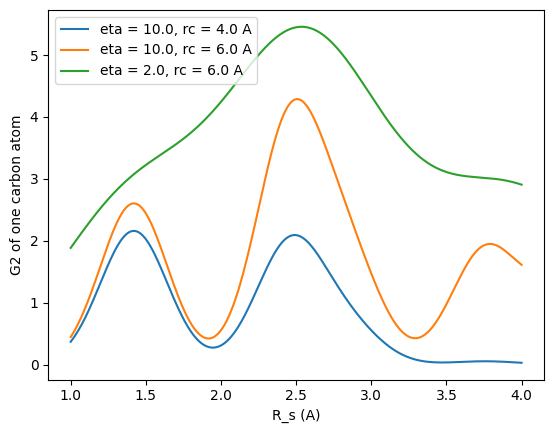

In [8]:
import numpy as np, matplotlib.pyplot as plt

fc = lambda r, rc: np.where(r < rc, 0.5 * (np.cos(np.pi * r / rc) + 1), 0.0)

d = 1.42
a1, a2 = d * np.array([1.5, np.sqrt(3) / 2]), d * np.array([1.5, -np.sqrt(3) / 2])   # lattice vectors
basis = [np.zeros(2), np.array([d, 0.0])]                                           # two atoms per cell
atoms = np.array([i * a1 + j * a2 + b for i in range(-4, 5) for j in range(-4, 5) for b in basis])
centre = atoms[np.argmin(np.linalg.norm(atoms, axis=1))]
r0j = np.linalg.norm(atoms - centre, axis=1); r0j = r0j[r0j > 1e-6]
for s in np.unique(r0j[r0j < 3.0].round(3)):
    print(f"shell at {s:.3f} A: {np.sum(np.isclose(r0j, s, atol=1e-3))} atoms")

Rs = np.linspace(1.0, 4.0, 400)
for eta, rc in [(10.0, 4.0), (10.0, 6.0), (2.0, 6.0)]:
    G2 = [np.sum(np.exp(-eta * (r0j - s)**2) * fc(r0j, rc)) for s in Rs]
    plt.plot(Rs, G2, label=f"eta = {eta}, rc = {rc} A")
plt.xlabel("R_s (A)"); plt.ylabel("G2 of one carbon atom"); plt.legend(); plt.show()

**Your turn.** Stretch the lattice by 2 % (multiply `d` by 1.02) and plot the difference in $G^2$. Where does the fingerprint change most? This is how an MLIP \"sees\" strain.

eta=10.0, rc=4.0: max |dG2| = 0.335 at R_s = 2.30 A
eta=10.0, rc=6.0: max |dG2| = 0.585 at R_s = 2.29 A
eta=2.0, rc=6.0: max |dG2| = 0.303 at R_s = 2.18 A


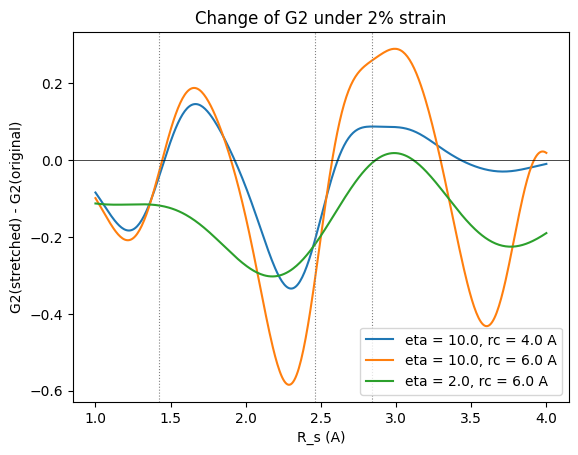

In [7]:
import numpy as np, matplotlib.pyplot as plt

fc = lambda r, rc: np.where(r < rc, 0.5 * (np.cos(np.pi * r / rc) + 1), 0.0)

def neighbour_distances(d):
    a1, a2 = d * np.array([1.5, np.sqrt(3) / 2]), d * np.array([1.5, -np.sqrt(3) / 2])
    basis = [np.zeros(2), np.array([d, 0.0])]
    atoms = np.array([i * a1 + j * a2 + b for i in range(-4, 5) for j in range(-4, 5) for b in basis])
    centre = atoms[np.argmin(np.linalg.norm(atoms, axis=1))]
    r0j = np.linalg.norm(atoms - centre, axis=1)
    return r0j[r0j > 1e-6]

d0 = 1.42
r0j_orig = neighbour_distances(d0)
r0j_str = neighbour_distances(d0 * 1.02)        # 2% stretch

Rs = np.linspace(1.0, 4.0, 400)
G2 = lambda r0j, eta, rc: np.array([np.sum(np.exp(-eta * (r0j - s)**2) * fc(r0j, rc)) for s in Rs])

for eta, rc in [(10.0, 4.0), (10.0, 6.0), (2.0, 6.0)]:
    dG = G2(r0j_str, eta, rc) - G2(r0j_orig, eta, rc)
    i = np.argmax(np.abs(dG))
    print(f"eta={eta}, rc={rc}: max |dG2| = {abs(dG[i]):.3f} at R_s = {Rs[i]:.2f} A")
    plt.plot(Rs, dG, label=f"eta = {eta}, rc = {rc} A")

for s in (1.42, 2.46, 2.84):                     # original shell positions
    plt.axvline(s, color="gray", ls=":", lw=0.8)
plt.axhline(0, color="k", lw=0.5)
plt.xlabel("R_s (A)"); plt.ylabel("G2(stretched) - G2(original)")
plt.title("Change of G2 under 2% strain"); plt.legend(); plt.show()

The fingerprint changes most near R_s ≈ 2.2–2.3 Å, just below the second-neighbour shell (2.46 Å → 2.51 Å).

Because stretching moves each shell outward by a small amount δ, so ΔG² ≈ −δ · dG²/dR_s. The change is therefore zero at the top of each peak, at 1.42 Å and 2.46 Å. It is largest on the flanks, where the curve is steepest:

ΔG² is negative on the rising side of a peak, for example at 2.3 Å. It is positive on the falling side, for example around 2.8–3.0 Å.
The biggest change is at the second shell because it has 6 atoms and moves the most (about 0.05 Å, compared with about 0.03 Å for the first shell).
With η = 10 the peaks are narrow, so the slopes are steeper and the changes bigger than with η = 2.

This is how an MLIP “sees” strain: a tiny change in bond lengths shows up as a clear change in G².

---
## Exercise 4. $G^4$: separating the angular and radial parts
For a symmetric triplet with bond length $b$ and angle $\theta$, $r_{jk}=2b\sin(\theta/2)$ and
$$G^4=\underbrace{2^{1-\zeta}(1+\lambda\cos\theta)^\zeta}_{\text{angular}}\;\underbrace{e^{-\eta(2b^2+r_{jk}^2)}}_{\text{radial}}\;f_c(b)^2f_c(r_{jk}).$$
Because $r_{jk}$ depends on $\theta$, the radial part also carries angular information. We see how $\eta$ reshapes $G^4(\theta)$ for $b=1.42$ Å (a C–C bond).

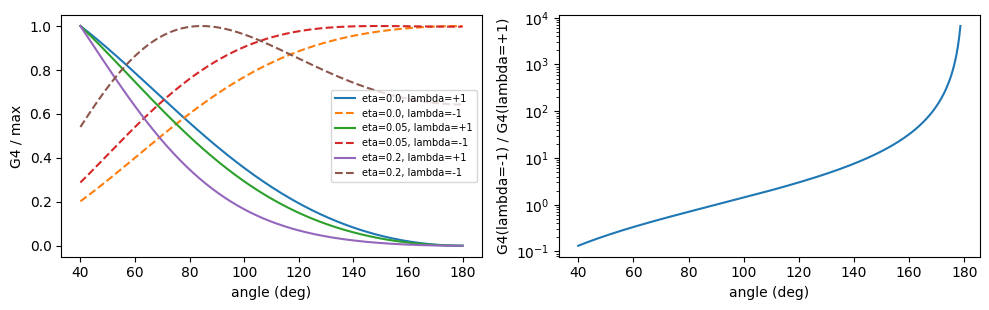

 90.0 deg: ratio =  1.000  -> recovered angle 90.0 deg
109.5 deg: ratio =  2.002  -> recovered angle 109.5 deg
120.0 deg: ratio =  3.000  -> recovered angle 120.0 deg
150.0 deg: ratio = 13.928  -> recovered angle 150.0 deg


In [9]:
import numpy as np, matplotlib.pyplot as plt

fc = lambda r, rc: np.where(r < rc, 0.5 * (np.cos(np.pi * r / rc) + 1), 0.0)
b, rc = 1.42, 6.0
theta = np.linspace(40, 180, 300); t = np.deg2rad(theta)
rjk = 2 * b * np.sin(t / 2)

def G4(zeta, lam, eta):
    return 2**(1 - zeta) * (1 + lam * np.cos(t))**zeta * np.exp(-eta * (2 * b**2 + rjk**2)) * fc(b, rc)**2 * fc(rjk, rc)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
for eta in (0.0, 0.05, 0.2):
    for lam, st in ((1, "-"), (-1, "--")):
        g = G4(1, lam, eta)
        ax[0].plot(theta, g / g.max(), st, label=f"eta={eta}, lambda={lam:+d}")
ax[0].set_xlabel("angle (deg)"); ax[0].set_ylabel("G4 / max"); ax[0].legend(fontsize=7)

g_plus, g_minus = G4(1, 1, 0.05), G4(1, -1, 0.05)
ok = theta < 179                                     # G4(lambda=+1) = 0 at exactly 180 deg
ax[1].plot(theta[ok], g_minus[ok] / g_plus[ok]); ax[1].set_yscale("log")
ax[1].set_xlabel("angle (deg)"); ax[1].set_ylabel("G4(lambda=-1) / G4(lambda=+1)")
plt.tight_layout(); plt.show()

for th in (90.0, 109.5, 120.0, 150.0):
    c = np.cos(np.deg2rad(th))
    ratio = (1 - c) / (1 + c)                           # tan^2(theta/2); diverges only at exactly 180 deg
    print(f"{th:5.1f} deg: ratio = {ratio:6.3f}  -> recovered angle {2 * np.degrees(np.arctan(np.sqrt(ratio))):.1f} deg")

**Your turn.** With $\eta=0.2$ the $\lambda=-1$ curve no longer peaks at $180^\circ$ but near $85^\circ$. Explain this shift from the $e^{-\eta r_{jk}^2}$ factor (which angles give a long $r_{jk}$?). Why does the ratio $G^4(\lambda=-1)/G^4(\lambda=+1)$ not depend on $\eta$ at all?

In [10]:
for eta in (0.0, 0.05, 0.2):
    g = G4(1, -1, eta)
    print(f"eta={eta}: lambda=-1 peak at {theta[np.argmax(g)]:.1f} deg")

eta=0.0: lambda=-1 peak at 180.0 deg
eta=0.05: lambda=-1 peak at 149.1 deg
eta=0.2: lambda=-1 peak at 84.5 deg


FIRST PART

ANSWER: G⁴ is a product of three parts: an angular part, an exponential part e^(−η·r_jk²), and a cutoff part f_c(r_jk). Here r_jk = 2b·sin(θ/2) is the distance between atoms j and k, so it grows as the angle θ grows.
1) For λ = −1 the angular part is (1 − cos θ), which is largest at 180°.
2) The exponential e^(−η·r_jk²) favours small r_jk, so it prefers small angles. At 180°, r_jk = 2.84 Å and the factor is about 0.20. At 85°, r_jk ≈ 1.92 Å and the factor is about 0.48.
3) When η = 0 the exponential equals 1, so the peak stays at 180°. When η = 0.2 the exponential wins, and the peak moves to about 85°.
4) The cutoff f_c(r_jk) also decreases as r_jk grows, which pushes the peak a bit lower still.

SECOND PART:

ANSWER: Both G⁴ values contain exactly the same exponential and cutoff factors. They cancel when you divide, and only the angular part remains:

(1 − cos θ)/(1 + cos θ) = tan²(θ/2)

This depends only on θ, not on η. That is why your code recovers the angle exactly from the ratio (for example, a ratio of 3.000 gives 120°).